# Mushroom

Inspect the UCI Mushroom dataset (id 73). Each row is one gilled mushroom from the Agaricus and Lepiota families. The features are physical characteristics stored as short codes, and `poisonous` is the class: `e` means edible, and `p` means poisonous. Mushrooms of unknown edibility are labeled poisonous.

The field guide says there is no simple rule for telling whether a mushroom is edible.

A logistic regression is the baseline. Each code is first turned into a number in the same column. Each code is then given a column of its own. Stratified 5-fold cross-validation then checks that column model on the training mushrooms.


## Trust the dataset download

`ucimlrepo` checks the UCI server with the `certifi` certificate bundle. On this machine Avast Web/Mail Shield scans HTTPS, so the server certificate is issued by Avast's local root. Windows already trusts that root, and `certifi` does not. The next cell keeps certificate checks on and uses the Windows trust store for this session so the download can succeed.


In [1]:
import ssl

if ssl.create_default_context.__name__ != "_create_default_context_windows_store":
    _create_default_context = ssl.create_default_context

    def _create_default_context_windows_store(*args, **kwargs):
        '''Use the OS trust store, which includes the Avast scanning root.'''
        return _create_default_context()

    ssl.create_default_context = _create_default_context_windows_store


## Load the dataset


In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
mushroom = fetch_ucirepo(id=73)

# data (as pandas dataframes)
X = mushroom.data.features
y = mushroom.data.targets

# metadata
print(mushroom.metadata)

# variable information
print(mushroom.variables)

df = X.copy()
df["poisonous"] = y.iloc[:, 0]


{'uci_id': 73, 'name': 'Mushroom', 'repository_url': 'https://archive.ics.uci.edu/dataset/73/mushroom', 'data_url': 'https://archive.ics.uci.edu/static/public/73/data.csv', 'abstract': 'From Audobon Society Field Guide; mushrooms described in terms of physical characteristics; classification: poisonous or edible', 'area': 'Biology', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 8124, 'num_features': 22, 'feature_types': ['Categorical'], 'demographics': [], 'target_col': ['poisonous'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1981, 'last_updated': 'Thu Aug 10 2023', 'dataset_doi': '10.24432/C5959T', 'creators': [], 'intro_paper': None, 'additional_info': {'summary': "This data set includes descriptions of hypothetical samples corresponding to 23 species of gilled mushrooms in the Agaricus and Lepiota Family (pp. 500-525).  Each species is identified as definitely edible, definitely po

## Inspect the data

`df` is the 22 features plus the class column `poisonous`. Every feature is a one-letter code. `stalk-root` is the only column with missing values, 2,480 of 8,124 rows. `veil-type` is partial (`p`) on every row. The variable table marks `cap-color` as binary, and that column has 10 colors.


In [3]:
print(df.head())
print(df.shape)
df.info()
print(df.describe())
print(df.isnull().sum())


  cap-shape cap-surface cap-color bruises odor gill-attachment gill-spacing  \
0         x           s         n       t    p               f            c   
1         x           s         y       t    a               f            c   
2         b           s         w       t    l               f            c   
3         x           y         w       t    p               f            c   
4         x           s         g       f    n               f            w   

  gill-size gill-color stalk-shape  ... stalk-color-above-ring  \
0         n          k           e  ...                      w   
1         b          k           e  ...                      w   
2         b          n           e  ...                      w   
3         n          n           e  ...                      w   
4         b          k           t  ...                      w   

  stalk-color-below-ring veil-type veil-color ring-number ring-type  \
0                      w         p          w           o

## Investigate the target

`poisonous` is `e` for edible and `p` for poisonous. This file has 4,208 edible mushrooms and 3,916 poisonous mushrooms.

Odor separates the classes almost completely. Almond (`a`) and anise (`l`) are edible, 400 mushrooms each. Creosote (`c`, 192), fishy (`y`, 576), foul (`f`, 2,160), musty (`m`, 36), pungent (`p`, 256), and spicy (`s`, 576) are poisonous. None (`n`) is the mixed odor: 3,408 edible and 120 poisonous.


In [4]:
print(df["poisonous"].value_counts().sort_index())
print()
print(df.groupby("odor")["poisonous"].value_counts().unstack(fill_value=0).sort_index())


poisonous
e    4208
p    3916
Name: count, dtype: int64

poisonous     e     p
odor                 
a           400     0
c             0   192
f             0  2160
l           400     0
m             0    36
n          3408   120
p             0   256
s             0   576
y             0   576


## Visualise relationships

The pairplot crosses odor, spore-print color, gill size, and population. Each feature is a category code, drawn at its own position and shifted slightly so mushrooms that share a code stay visible. Edible mushrooms are green and poisonous mushrooms are red.

The tall green bar on odor none is the edible majority. The red bars on foul, fishy, and spicy are poisonous. Black and brown spore prints are mostly edible. Chocolate and white spore prints are mostly poisonous, and green is poisonous. Broad gills are mostly edible. Narrow gills are mostly poisonous. Abundant and numerous populations are edible. The several population is mostly poisonous.


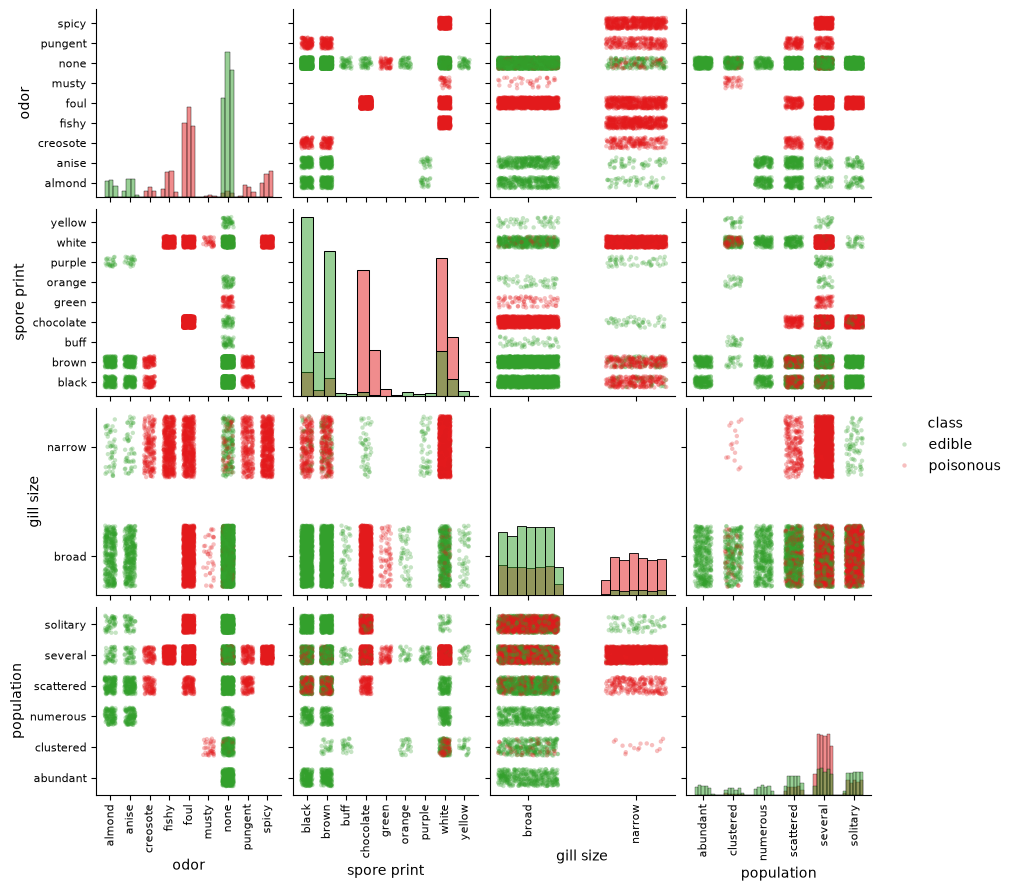

In [5]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

levels = {
    "odor": [
        ("a", "almond"),
        ("l", "anise"),
        ("c", "creosote"),
        ("y", "fishy"),
        ("f", "foul"),
        ("m", "musty"),
        ("n", "none"),
        ("p", "pungent"),
        ("s", "spicy"),
    ],
    "spore-print-color": [
        ("k", "black"),
        ("n", "brown"),
        ("b", "buff"),
        ("h", "chocolate"),
        ("r", "green"),
        ("o", "orange"),
        ("u", "purple"),
        ("w", "white"),
        ("y", "yellow"),
    ],
    "gill-size": [
        ("b", "broad"),
        ("n", "narrow"),
    ],
    "population": [
        ("a", "abundant"),
        ("c", "clustered"),
        ("n", "numerous"),
        ("s", "scattered"),
        ("v", "several"),
        ("y", "solitary"),
    ],
}
axis_names = {
    "odor": "odor",
    "spore-print-color": "spore print",
    "gill-size": "gill size",
    "population": "population",
}

rng = np.random.default_rng(0)
plot_df = pd.DataFrame(index=df.index)
for column, pairs in levels.items():
    code = df[column].map({letter: i for i, (letter, _name) in enumerate(pairs)}).astype(float)
    plot_df[axis_names[column]] = code + rng.uniform(-0.28, 0.28, len(df))
plot_df["class"] = df["poisonous"].map({"e": "edible", "p": "poisonous"})

grid = sns.pairplot(
    plot_df,
    hue="class",
    hue_order=["edible", "poisonous"],
    palette={"edible": "#33A02C", "poisonous": "#E31A1C"},
    diag_kind="hist",
    height=2.15,
    plot_kws={"s": 10, "alpha": 0.28, "linewidth": 0},
)

label_lists = [[name for _letter, name in pairs] for pairs in levels.values()]
n = len(label_lists)
for i in range(n):
    for j in range(n):
        ax = grid.axes[i, j]
        ax.set_xticks(range(len(label_lists[j])))
        ax.set_yticks(range(len(label_lists[i])))
        if i == n - 1:
            ax.set_xticklabels(label_lists[j], rotation=90, fontsize=8)
        if j == 0:
            ax.set_yticklabels(label_lists[i], fontsize=8)

plt.show()


## Train and test split

Hold out 20% of the mushrooms. Stratify on `poisonous` so edible and poisonous keep the same share in both sets.

`veil-type` is left out. It is partial on every mushroom.


In [6]:
from sklearn.model_selection import train_test_split

features = df.drop(columns=["poisonous", "veil-type"])
labels = df["poisonous"]

X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.2, random_state=42, stratify=labels
)
print("Train:", X_train.shape[0], "Test:", X_test.shape[0])
print(y_train.value_counts().sort_index())
print(y_test.value_counts().sort_index())


Train: 6499 Test: 1625
poisonous
e    3366
p    3133
Name: count, dtype: int64
poisonous
e    842
p    783
Name: count, dtype: int64


## A number in the same column

Each letter stays in its column and becomes an integer. The integers follow the alphabetical order of the codes in the training mushrooms. A missing `stalk-root` is recorded as `missing` before that numbering, so the gap keeps a number of its own. The table stays 21 columns.


In [7]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder

imputer = SimpleImputer(strategy="constant", fill_value="missing")
encoder = OrdinalEncoder()

X_train_filled = imputer.fit_transform(X_train)
X_test_filled = imputer.transform(X_test)
X_train_numbers = encoder.fit_transform(X_train_filled)
X_test_numbers = encoder.transform(X_test_filled)

odor_index = list(X_train.columns).index("odor")
print("odor:", list(encoder.categories_[odor_index]))
print("Training table:", X_train_numbers.shape)
print("Held-out table:", X_test_numbers.shape)


odor: ['a', 'c', 'f', 'l', 'm', 'n', 'p', 's', 'y']
Training table: (6499, 21)
Held-out table: (1625, 21)


## Logistic regression

Logistic regression is fit on those 21 numbers. One weight per column treats the alphabetical order as a scale.


In [8]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=10000)
model.fit(X_train_numbers, y_train)
print("Fitted logistic regression")


Fitted logistic regression


## Evaluate the code numbers

The model is scored on the 1,625 held-out mushrooms. Accuracy is compared with always predicting the most common training class. The confusion matrix shows which class the model actually chooses.


Accuracy: 0.961
Always predict e: 0.518

              precision    recall  f1-score   support

      edible       0.96      0.96      0.96       842
   poisonous       0.96      0.96      0.96       783

    accuracy                           0.96      1625
   macro avg       0.96      0.96      0.96      1625
weighted avg       0.96      0.96      0.96      1625



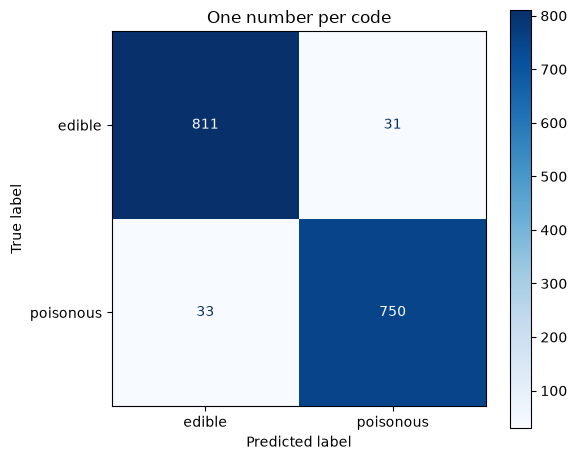

In [9]:
import numpy as np

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
)

y_pred = model.predict(X_test_numbers)
held_out = y_test.to_numpy()
predicted = np.asarray(y_pred)
common_class = y_train.mode().iloc[0]
majority = np.full(len(held_out), common_class)
class_names = ["edible", "poisonous"]

print(f"Accuracy: {accuracy_score(held_out, predicted):.3f}")
print(f"Always predict {common_class}: {accuracy_score(held_out, majority):.3f}")
print()
print(classification_report(
    held_out,
    predicted,
    labels=["e", "p"],
    target_names=class_names,
    zero_division=0,
))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    held_out,
    predicted,
    labels=["e", "p"],
    display_labels=class_names,
    ax=ax,
    cmap="Blues",
)
ax.set_title("One number per code")
fig.tight_layout()
plt.show()


## What the numbers catch

On the 1,625 held-out mushrooms, accuracy is 0.961. Always predicting edible scores 0.518.

Of the 842 edible mushrooms, 811 are called edible and 31 are called poisonous. Of the 783 poisonous mushrooms, 750 are called poisonous and 33 are called edible. Precision and recall round to 0.96.

The printed odor order is `a`, `c`, `f`, `l`, `m`, `n`, `p`, `s`, `y`. Almond and anise are edible, and poisonous codes sit between them. One weight on that column treats the list as a single scale.


## Each code becomes a column

The alphabetical number is replaced by a column for each code. A missing `stalk-root` is again recorded as `missing`. The imputer and the encoder are fit on the training mushrooms, and the held-out mushrooms pass through the same steps. The training table grows from 21 columns to 116. Logistic regression is fit again on that table.


In [10]:
from sklearn.preprocessing import OneHotEncoder

imputer = SimpleImputer(strategy="constant", fill_value="missing")
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

X_train_filled = imputer.fit_transform(X_train)
X_test_filled = imputer.transform(X_test)
X_train_codes = encoder.fit_transform(X_train_filled)
X_test_codes = encoder.transform(X_test_filled)

model = LogisticRegression(max_iter=10000)
model.fit(X_train_codes, y_train)
print("Training table:", X_train_codes.shape)
print("Held-out table:", X_test_codes.shape)
print("Fitted logistic regression")


Training table: (6499, 116)
Held-out table: (1625, 116)
Fitted logistic regression


## Evaluate the separate columns

The same 1,625 mushrooms are scored again. Accuracy is compared with always predicting the most common training class, and with the code-number model.


Accuracy: 0.999
Always predict e: 0.518

              precision    recall  f1-score   support

      edible       1.00      1.00      1.00       842
   poisonous       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



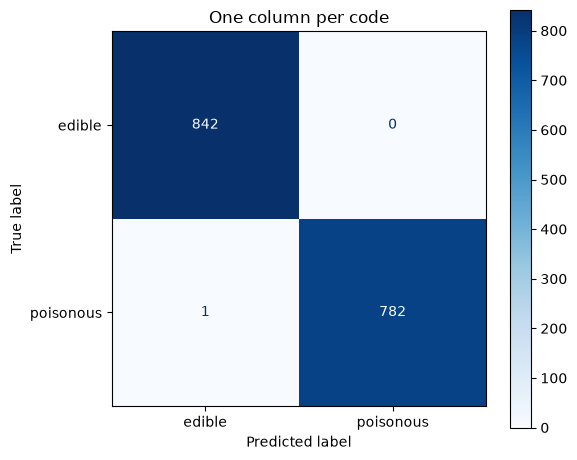

In [11]:
import numpy as np

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
)

y_pred = model.predict(X_test_codes)
held_out = y_test.to_numpy()
predicted = np.asarray(y_pred)
common_class = y_train.mode().iloc[0]
majority = np.full(len(held_out), common_class)
class_names = ["edible", "poisonous"]

print(f"Accuracy: {accuracy_score(held_out, predicted):.3f}")
print(f"Always predict {common_class}: {accuracy_score(held_out, majority):.3f}")
print()
print(classification_report(
    held_out,
    predicted,
    labels=["e", "p"],
    target_names=class_names,
    zero_division=0,
))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    held_out,
    predicted,
    labels=["e", "p"],
    display_labels=class_names,
    ax=ax,
    cmap="Blues",
)
ax.set_title("One column per code")
fig.tight_layout()
plt.show()


## What the separate columns add

On the same 1,625 mushrooms, accuracy rises from 0.961 to 0.999. Always predicting edible still scores 0.518.

The number encoding misses 64 mushrooms: 31 edible called poisonous, and 33 poisonous called edible. The separate columns miss one poisonous mushroom, and it has odor none. All 842 edible mushrooms are called edible. Precision and recall for both classes round to 1.00.


## Cross-validation

The 1,625 held-out mushrooms stay unused here. Stratified 5-fold cross-validation resplits only the 6,499 training rows. Each fold scores about 1,300 mushrooms, with the same share of edible and poisonous mushrooms in every fold. The imputer and the encoder are fit inside the fold, on that fold's training rows only.


In [12]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

cv_model = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ("classifier", LogisticRegression(max_iter=10000)),
    ]
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(cv_model, X_train, y_train, cv=cv, scoring="accuracy")

print("Stratified 5-fold accuracy on the 6,499 training mushrooms")
print()
folds = ", ".join(f"{score:.3f}" for score in scores)
print(f"folds: {folds}")
print(f"mean:  {scores.mean():.3f}   std: {scores.std():.3f}")


Stratified 5-fold accuracy on the 6,499 training mushrooms

folds: 0.997, 1.000, 1.000, 1.000, 1.000
mean:  0.999   std: 0.001


## The folds agree

Four folds score 1.000. The other scores 0.997, four misses in 1,300 mushrooms. The mean is 0.999, with a standard deviation of 0.001. The 1,625 held-out mushrooms scored 0.999 as well.


## Conclusion

The data are 8,124 mushrooms and 22 physical characteristics, stored as short codes. `poisonous` is the class: `e` means edible, and `p` means poisonous. 6,499 mushrooms train the models and 1,625 are held out. Edible is the common class in that held-out set: always predicting edible scores 0.518.

A logistic regression that turns each code into a number in the same column reaches accuracy 0.961. `veil-type` is left out, because it is partial on every mushroom, so the table stays 21 columns. Of the 842 edible mushrooms, 811 are called edible and 31 are called poisonous. Of the 783 poisonous mushrooms, 750 are called poisonous and 33 are called edible. Precision and recall round to 0.96. One weight on odor treats almond, anise, and the poisonous codes as a single scale.

Each code is then given a column of its own. A missing `stalk-root` is recorded as `missing`, and the training table grows from 21 columns to 116. On the same 1,625 mushrooms, accuracy rises to 0.999. The separate columns miss one poisonous mushroom, and it has odor none. All 842 edible mushrooms are called edible.

Stratified 5-fold cross-validation on the 6,499 training mushrooms, with the imputer and the encoder fit inside each fold, scores 0.997, 1.000, 1.000, 1.000, and 1.000. The mean is 0.999, with a standard deviation of 0.001.
